Local file 'Stock_Prices.csv' not found. Creating a sample stock price dataset for demonstration...

Initial DataFrame Head:
        Date       Close   Volume
0 2025-01-01  151.093428  2803649
1 2025-01-02  150.916900  2224665
2 2025-01-03  152.312277  3294544
3 2025-01-06  155.458336  5353127
4 2025-01-07  155.090030  6635882

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    200 non-null    datetime64[ns]
 1   Close   200 non-null    float64       
 2   Volume  200 non-null    int32         
dtypes: datetime64[ns](1), float64(1), int32(1)
memory usage: 4.0 KB
None


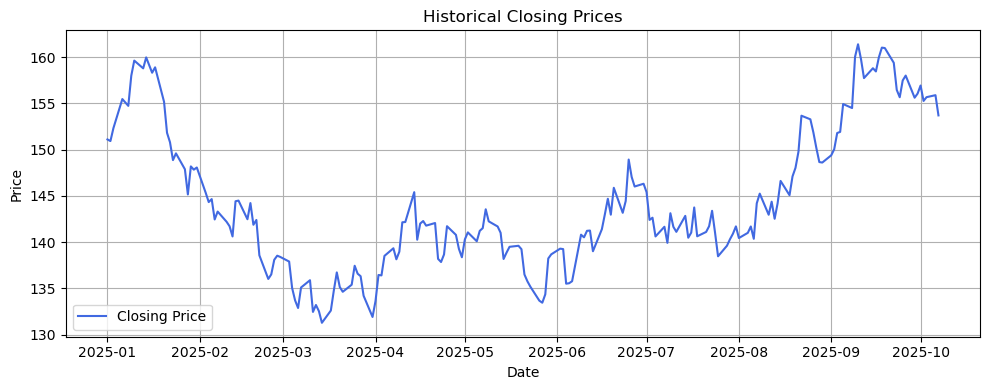

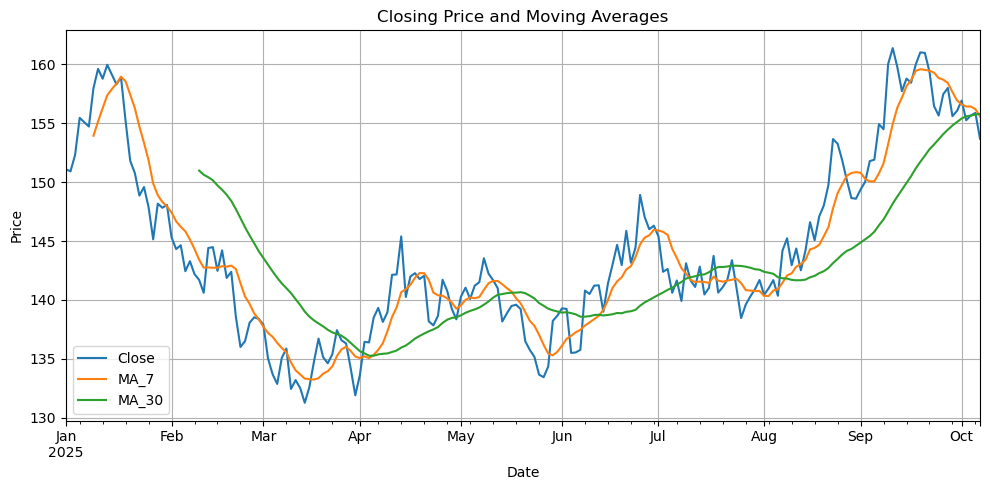

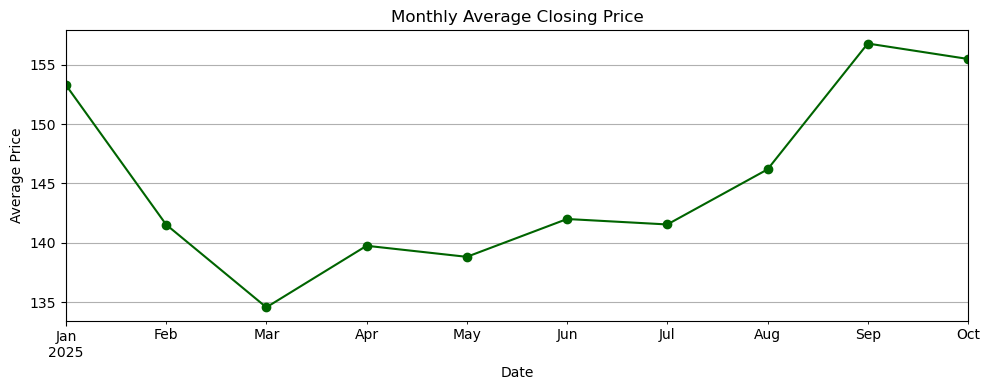


Correlation Matrix:
            Close    Volume
Close   1.000000  0.061921
Volume  0.061921  1.000000


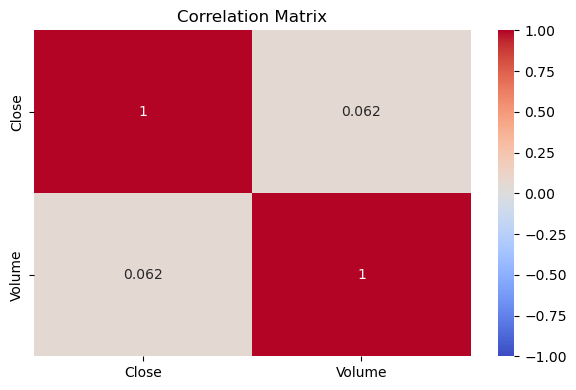


Forecast for next 10 observations:
 2025-10-08    153.828547
2025-10-09    153.898918
2025-10-10    153.935083
2025-10-13    153.953669
2025-10-14    153.963220
2025-10-15    153.968129
2025-10-16    153.970651
2025-10-17    153.971948
2025-10-20    153.972614
2025-10-21    153.972956
Freq: B, Name: predicted_mean, dtype: float64


C:\Users\Devesh Mulani\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)
C:\Users\Devesh Mulani\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)
C:\Users\Devesh Mulani\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency B will be used.
  self._init_dates(dates, freq)


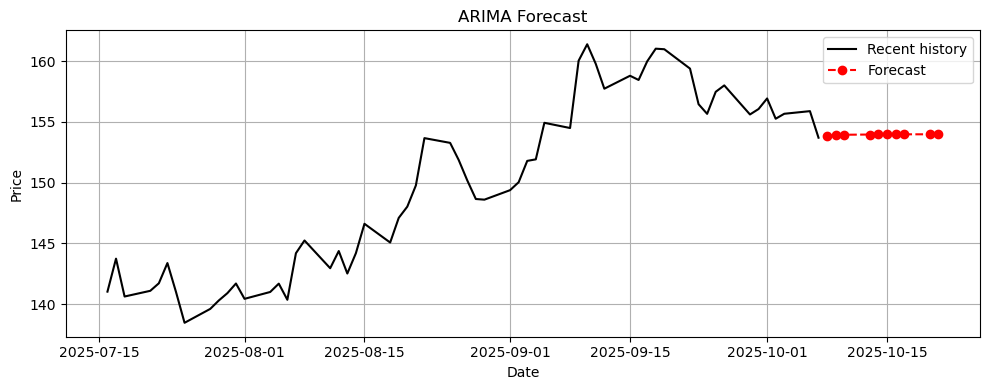

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
try:
    df = pd.read_csv("Stock_Prices.csv")
    print("Successfully loaded 'Stock_Prices.csv' from local storage.")
except FileNotFoundError:
    print("Local file 'Stock_Prices.csv' not found. Creating a sample stock price dataset for demonstration...")
    
    np.random.seed(42)
    dates = pd.date_range(start="2025-01-01", periods=200, freq="B")
    prices = 150 + np.cumsum(np.random.normal(0.1, 2.0, size=200))
    volumes = np.random.randint(1000000, 8000000, size=200)
    
    df = pd.DataFrame({
        "Date": dates,
        "Close": prices,
        "Volume": volumes
    })
print("\nInitial DataFrame Head:")
print(df.head())
print("\nDataFrame Info:")
print(df.info())

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Close"] = pd.to_numeric(df["Close"], errors="coerce")
df = df.dropna(subset=["Date", "Close"]).sort_values("Date")
df = df.drop_duplicates(subset=["Date"]).set_index("Date")
plt.figure(figsize=(10, 4))
plt.plot(df.index, df["Close"], label="Closing Price", color="royalblue")
plt.title("Historical Closing Prices")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
df["MA_7"] = df["Close"].rolling(7).mean()
df["MA_30"] = df["Close"].rolling(30).mean()
df[["Close", "MA_7", "MA_30"]].plot(figsize=(10, 5), title="Closing Price and Moving Averages")
plt.ylabel("Price")
plt.grid(True)
plt.tight_layout()
plt.show()

monthly = df["Close"].resample("ME").mean()
monthly.plot(title="Monthly Average Closing Price", figsize=(10, 4), marker="o", color="darkgreen")
plt.ylabel("Average Price")
plt.grid(True)
plt.tight_layout()
plt.show()

cols = ["Close"]
if "Volume" in df.columns:
    df["Volume"] = pd.to_numeric(df["Volume"], errors="coerce")
    cols.append("Volume")

corr = df[cols].corr()
print("\nCorrelation Matrix:\n", corr)
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

series = df["Close"].dropna().astype(float)
if len(series) >= 20:
    model = ARIMA(series, order=(1, 1, 1)).fit()
    forecast = model.forecast(steps=10)
    print("\nForecast for next 10 observations:\n", forecast)
    plt.figure(figsize=(10, 4))
    plt.plot(series.tail(60).index, series.tail(60), label="Recent history", color="black")
    forecast_dates = pd.date_range(start=series.index[-1] + pd.Timedelta(days=1), periods=10, freq="B")
    forecast.index = forecast_dates
    
    plt.plot(forecast.index, forecast, marker="o", label="Forecast", color="red", linestyle="--")
    plt.legend()
    plt.title("ARIMA Forecast")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("At least 20 valid observations are recommended for this example.")

In [ ]:
Name - Devesh Mulani
Roll number - 4141